# Efficient ResNet for CIFAR-10 (under 5M parameters)

Deep Learning, Fall 2026, Project 1.

This notebook trains modified ResNets **from scratch** on the course CIFAR-10 training set, compares three configurations, and writes `submission.csv` for the Kaggle test set.

**How to run (Google Colab, GPU runtime):**
1. Put `data-2.zip` (the Kaggle data) anywhere in your Google Drive.
2. `Runtime > Change runtime type > T4 GPU`, then `Runtime > Run all`.

Every epoch is checkpointed to Drive, so if the session disconnects, just run all cells again: finished experiments are loaded from disk and an interrupted one resumes where it stopped.

## 1. Setup

In [1]:
import os, glob, json, time, math, zipfile, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

SMOKE_TEST = False   # True: 2 epochs per experiment, only to check that everything runs

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "no GPU")
torch.backends.cudnn.benchmark = True

PyTorch 2.14.1+cu130 | device: cuda | Tesla T4


In [2]:
# Paths. On Colab the data zip is read from Google Drive and results are saved back to Drive.
# Outside Colab, set DATA_DIR / OUT_DIR environment variables instead.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

DRIVE = "/content/drive/MyDrive"
DATA_DIR = os.environ.get("DATA_DIR", "/content/data")
OUT_DIR = os.environ.get("OUT_DIR", f"{DRIVE}/dl-project1/runs" if IN_COLAB else "./runs")
if SMOKE_TEST:
    OUT_DIR += "_smoke"
os.makedirs(OUT_DIR, exist_ok=True)

def find_file(root, name):
    hits = [p for p in glob.glob(os.path.join(root, "**", name), recursive=True) if "__MACOSX" not in p]
    return hits[0] if hits else None

if find_file(DATA_DIR, "train_labels.csv") is None:
    zip_path = find_file(DRIVE, "data-2.zip") or find_file(DRIVE, "*.zip")
    assert zip_path, "data-2.zip not found in Google Drive"
    print("Unzipping", zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

DATA_ROOT = os.path.dirname(find_file(DATA_DIR, "train_labels.csv"))
print("Data folder:", DATA_ROOT, "->", sorted(os.listdir(DATA_ROOT)))
print("Results folder:", OUT_DIR)

Mounted at /content/drive
Unzipping /content/drive/MyDrive/dl-project1/data-2.zip
Data folder: /content/data/data-2 -> ['.DS_Store', 'sample_submission.csv', 'test.csv', 'test_images', 'train_images', 'train_labels.csv']
Results folder: /content/drive/MyDrive/dl-project1/runs


## 2. Data

The PNG images are read once into memory (50,000 training and 2,000 test images of 32×32×3) and cached as `.npy`. The labelled data is split, stratified by class, into **45,000 training** and **5,000 hold-out** images. The hold-out images are never used for training; they give the validation curves and the final test accuracy reported below.

In [3]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

def load_images(folder, filenames, cache):
    if os.path.exists(cache):
        return np.load(cache)
    arr = np.stack([np.array(Image.open(os.path.join(folder, f)).convert("RGB")) for f in filenames])
    np.save(cache, arr)
    return arr

train_df = pd.read_csv(os.path.join(DATA_ROOT, "train_labels.csv"))
test_df = pd.read_csv(os.path.join(DATA_ROOT, "test.csv"))

t0 = time.time()
X_all = load_images(os.path.join(DATA_ROOT, "train_images"), train_df.filename, os.path.join(DATA_DIR, "train.npy"))
X_test = load_images(os.path.join(DATA_ROOT, "test_images"), test_df.filename, os.path.join(DATA_DIR, "test.npy"))
y_all = train_df.label.values.astype(np.int64)
print(f"Loaded in {time.time() - t0:.0f}s | train {X_all.shape} | test {X_test.shape}")
print("Images per class:", np.bincount(y_all))

Loaded in 10s | train (50000, 32, 32, 3) | test (2000, 32, 32, 3)
Images per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


In [4]:
# Stratified split with a fixed seed: 10% of every class goes to the hold-out set.
rng = np.random.RandomState(0)
holdout_idx = np.sort(np.concatenate([
    rng.choice(np.where(y_all == c)[0], size=int(0.1 * (y_all == c).sum()), replace=False)
    for c in range(10)]))
train_idx = np.setdiff1d(np.arange(len(y_all)), holdout_idx)
print("train:", len(train_idx), "| hold-out:", len(holdout_idx))

# Channel mean / std from the training split only.
MEAN = X_all[train_idx].mean(axis=(0, 1, 2)) / 255
STD = X_all[train_idx].std(axis=(0, 1, 2)) / 255
print("mean", MEAN.round(4), "std", STD.round(4))

def to_gpu(x):  # uint8 NHWC numpy -> uint8 NCHW tensor on the device
    return torch.from_numpy(x).permute(0, 3, 1, 2).contiguous().to(device)

# The whole dataset is ~150 MB, so it lives on the GPU and batches are built there.
Xtr, ytr = to_gpu(X_all[train_idx]), torch.from_numpy(y_all[train_idx]).to(device)
Xho, yho = to_gpu(X_all[holdout_idx]), torch.from_numpy(y_all[holdout_idx]).to(device)
Xte = to_gpu(X_test)
mean_t = torch.tensor(MEAN, dtype=torch.float32, device=device).view(1, 3, 1, 1)
std_t = torch.tensor(STD, dtype=torch.float32, device=device).view(1, 3, 1, 1)

def normalize(x_uint8):
    return (x_uint8.float() / 255 - mean_t) / std_t

train: 45000 | hold-out: 5000
mean [0.4915 0.4822 0.4467] std [0.247  0.2435 0.2615]


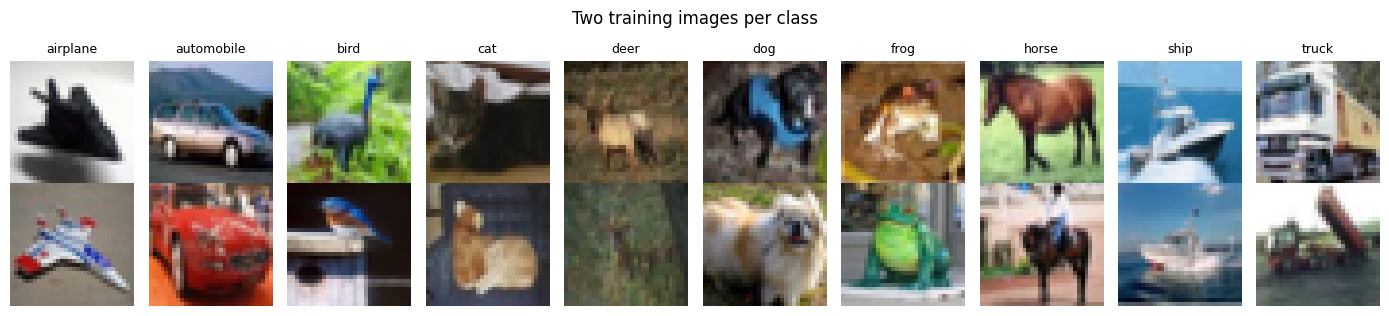

In [5]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c in range(10):
    for r in range(2):
        axes[r, c].imshow(X_all[np.where(y_all == c)[0][r]])
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle("Two training images per class"); plt.tight_layout(); plt.show()

### Data augmentation

Augmentation is applied per batch on the GPU (Colab has only two CPU cores, so a CPU data loader would be the bottleneck):

* **Random crop**: pad 4 pixels on each side (reflection), then take a random 32×32 crop.
* **Random horizontal flip** with probability 0.5.
* **Cutout** (optional, DeVries & Taylor 2017): zero out one random square patch per image.

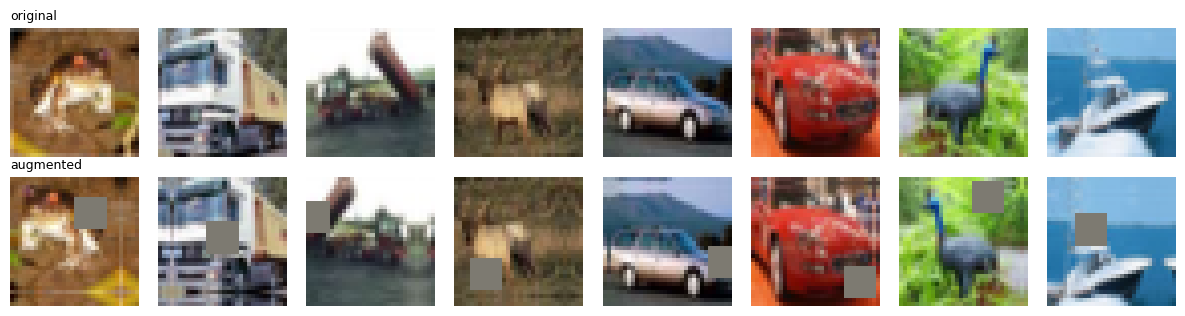

In [6]:
def augment(x, cutout=0):
    # x: normalized float batch (B, 3, 32, 32) on the device
    B = x.size(0)
    # horizontal flip
    flip = torch.rand(B, device=x.device) < 0.5
    x = torch.where(flip.view(B, 1, 1, 1), x.flip(3), x)
    # random crop from the 40x40 padded image, with a different offset per image
    xp = F.pad(x, (4, 4, 4, 4), mode="reflect")
    ar = torch.arange(32, device=x.device)
    rows = torch.randint(0, 9, (B, 1), device=x.device) + ar          # (B, 32)
    cols = torch.randint(0, 9, (B, 1), device=x.device) + ar          # (B, 32)
    b = torch.arange(B, device=x.device).view(B, 1, 1)
    x = xp.permute(0, 2, 3, 1)[b, rows.view(B, 32, 1), cols.view(B, 1, 32)].permute(0, 3, 1, 2)
    # cutout: a square of side `cutout` centred at a random pixel (clipped at the border)
    if cutout > 0:
        y0 = torch.randint(0, 32, (B, 1, 1), device=x.device) - cutout // 2
        x0 = torch.randint(0, 32, (B, 1, 1), device=x.device) - cutout // 2
        yy, xx = ar.view(1, 32, 1), ar.view(1, 1, 32)
        hole = (yy >= y0) & (yy < y0 + cutout) & (xx >= x0) & (xx < x0 + cutout)
        x = x.masked_fill(hole.unsqueeze(1), 0.0)
    return x.contiguous()

torch.manual_seed(0)
demo = augment(normalize(Xtr[:8]), cutout=8)
demo = (demo * std_t + mean_t).clamp(0, 1).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    axes[0, i].imshow(Xtr[i].permute(1, 2, 0).cpu().numpy()); axes[0, i].axis("off")
    axes[1, i].imshow(demo[i]); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left"); axes[1, 0].set_title("augmented", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

### Stronger augmentation (used only in experiment 4)

Experiment 4 tests whether a model trained on more varied images generalizes better to the shifted Kaggle test set. Before the crop / flip / cutout above, each image is randomly perturbed with generic photometric and geometric changes:

* rotation (±15°) and zoom (0.8× to 1.2×), applied to half of the images
* brightness, contrast and saturation jitter (factors in 0.6 to 1.4)
* grayscale conversion (10% of images), blur (20%), additive Gaussian noise (30%)

These are standard robustness augmentations chosen without looking at the test images.

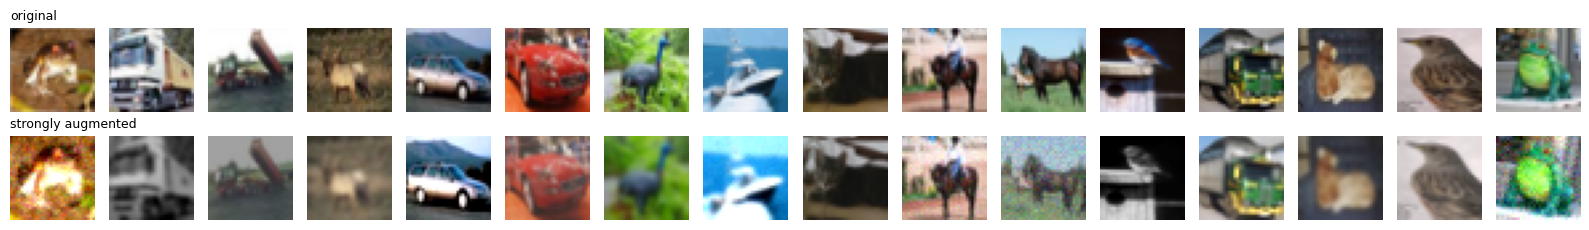

In [7]:
def strong_augment(x):
    # x: float batch in [0, 1], shape (B, 3, 32, 32)
    B, dev = x.size(0), x.device
    u = lambda lo, hi: torch.rand(B, 1, 1, 1, device=dev) * (hi - lo) + lo
    pick = lambda p: torch.rand(B, 1, 1, 1, device=dev) < p

    # rotation + zoom
    ang = u(-15, 15).view(B) * math.pi / 180
    inv = 1 / u(0.8, 1.2).view(B)
    theta = torch.zeros(B, 2, 3, device=dev)
    theta[:, 0, 0] = torch.cos(ang) * inv; theta[:, 0, 1] = -torch.sin(ang) * inv
    theta[:, 1, 0] = torch.sin(ang) * inv; theta[:, 1, 1] = torch.cos(ang) * inv
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    warped = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
    x = torch.where(pick(0.5), warped, x)

    # brightness, contrast, saturation
    x = x * u(0.6, 1.4)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - m) * u(0.6, 1.4) + m
    gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
    x = (x - gray) * u(0.6, 1.4) + gray
    x = torch.where(pick(0.1), gray.expand_as(x), x)

    # blur (3x3 binomial kernel)
    k = torch.tensor([1., 2., 1.], device=dev) / 4
    kernel = (k[:, None] * k[None, :]).expand(3, 1, 3, 3).contiguous()
    blurred = F.conv2d(F.pad(x, (1, 1, 1, 1), mode="reflect"), kernel, groups=3)
    x = torch.where(pick(0.2), blurred, x)

    # Gaussian noise
    x = torch.where(pick(0.3), x + torch.randn_like(x) * u(0.0, 0.08), x)
    return x.clamp(0, 1)

torch.manual_seed(0)
demo = strong_augment(Xtr[:16].float() / 255).permute(0, 2, 3, 1).cpu().numpy()
fig, axes = plt.subplots(2, 16, figsize=(16, 2.4))
for i in range(16):
    axes[0, i].imshow(Xtr[i].permute(1, 2, 0).cpu().numpy()); axes[0, i].axis("off")
    axes[1, i].imshow(demo[i]); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=9, loc="left"); axes[1, 0].set_title("strongly augmented", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

## 3. Model

A ResNet built from the basic residual block of He et al. (2016):

$$\text{out} = \mathrm{ReLU}\big(S(x) + F(x)\big), \qquad F = \text{conv} \to \text{BN} \to \text{ReLU} \to \text{conv} \to \text{BN}$$

$S(x)$ is the identity when the shape is unchanged, and a 1×1 convolution + BN when the block changes the number of channels or downsamples.

Compared with ResNet-18, the network keeps the 3×3 stem without max-pooling (the images are only 32×32) and uses **three stages instead of four**. The fourth 512-channel stage of ResNet-18 alone has about 8.4M parameters, so dropping it is what brings the model under the 5M limit.

| Model | Stage widths | Blocks per stage |
|---|---|---|
| A | 64, 128, 256 | 2, 2, 2 |
| B | 64, 128, 256 | 3, 3, 3 |

In [8]:
class BasicBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Sequential()                       # S(x) = x
        if stride != 1 or in_ch != out_ch:                    # S(x) = BN(conv1x1(x))
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class ResNet(nn.Module):
    def __init__(self, widths=(64, 128, 256), blocks=(2, 2, 2), num_classes=10):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        layers, in_ch = [], widths[0]
        for i, (w, n) in enumerate(zip(widths, blocks)):
            for j in range(n):
                stride = 2 if (j == 0 and i > 0) else 1       # downsample at the start of stages 2 and 3
                layers.append(BasicBlock(in_ch, w, stride))
                in_ch = w
        self.layers = nn.Sequential(*layers)
        self.fc = nn.Linear(in_ch, num_classes)

    def forward(self, x):
        x = self.layers(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)            # global average pool
        return self.fc(x)


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

MODELS = {
    "A": dict(widths=(64, 128, 256), blocks=(2, 2, 2)),
    "B": dict(widths=(64, 128, 256), blocks=(3, 3, 3)),
}
PARAM_LIMIT = 5_000_000
for name, cfg in MODELS.items():
    n = count_params(ResNet(**cfg))
    assert n <= PARAM_LIMIT, f"model {name} has {n:,} parameters, over the limit"
    print(f"Model {name}: {n:,} trainable parameters ({n / 1e6:.2f}M) - under the 5M limit")

Model A: 2,777,674 trainable parameters (2.78M) - under the 5M limit
Model B: 4,327,754 trainable parameters (4.33M) - under the 5M limit


## 4. Training

All experiments share the same optimizer settings, so the comparison isolates augmentation/regularization (1 vs 2) and depth (2 vs 3):

* SGD with Nesterov momentum 0.9, batch size 128, weight decay 5e-4
* peak learning rate 0.1, linear warm-up for 2 epochs, then cosine decay to 0
* mixed precision (AMP) for speed

In [9]:
@torch.no_grad()
def predict_proba(model, X, tta=False, bs=1000):
    # class probabilities; with tta=True, averaged over the image and its horizontal flip
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        x = normalize(X[i:i + bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            p = model(x).float().softmax(1)
            if tta:
                p = (p + model(x.flip(3)).float().softmax(1)) / 2
        out.append(p)
    return torch.cat(out)

def evaluate(model, X, y, tta=False):
    p = predict_proba(model, X, tta)
    loss = F.nll_loss(p.clamp_min(1e-12).log(), y).item()
    acc = (p.argmax(1) == y).float().mean().item() * 100
    return loss, acc

In [10]:
def run_experiment(name, model="A", epochs=40, cutout=0, label_smoothing=0.0,
                   lr=0.1, weight_decay=5e-4, batch_size=128, warmup_epochs=2, seed=0, strong_aug=False):
    # Train one configuration. Returns (model, history).
    # A checkpoint is written to OUT_DIR/<name>/ after every epoch, so the run can be resumed.
    config = {k: v for k, v in locals().items() if k != "name"}
    if not strong_aug:
        del config["strong_aug"]      # keeps the configs of experiments 1-3 identical to their saved checkpoints
    run_dir = os.path.join(OUT_DIR, name)
    os.makedirs(run_dir, exist_ok=True)
    ckpt_path = os.path.join(run_dir, "checkpoint.pt")

    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    net = ResNet(**MODELS[model]).to(device).to(memory_format=torch.channels_last)
    n_params = count_params(net)
    assert n_params <= PARAM_LIMIT

    steps_per_epoch = len(Xtr) // batch_size
    total = epochs * steps_per_epoch
    warm = min(warmup_epochs, epochs - 1) * steps_per_epoch
    opt = torch.optim.SGD(net.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * min(1.0, (s - warm) / (total - warm)))))
    scaler = torch.amp.GradScaler(device.type, enabled=device.type == "cuda")
    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

    history, start = [], 0
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device)
        if ck["config"] == config:
            net.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
            sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
            history, start = ck["history"], len(ck["history"])
        else:
            print("Config changed since the saved checkpoint -> training from scratch")

    print(f"[{name}] model {model}, {n_params:,} parameters | {config}")
    if start:
        print(f"[{name}] found checkpoint with {start}/{epochs} epochs done")
        for h in history:
            if h["epoch"] % 5 == 0 or h["epoch"] == epochs:
                print(f"  epoch {h['epoch']:3d} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.2f}% "
                      f"| hold-out loss {h['val_loss']:.3f} acc {h['val_acc']:.2f}% (saved)")

    for epoch in range(start, epochs):
        net.train()
        t0 = time.time()
        perm = torch.randperm(len(Xtr), device=device)
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device)
        for i in range(steps_per_epoch):
            idx = perm[i * batch_size:(i + 1) * batch_size]
            x = Xtr[idx].float() / 255
            if strong_aug:
                x = strong_augment(x)
            x = augment((x - mean_t) / std_t, cutout).contiguous(memory_format=torch.channels_last)
            y = ytr[idx]
            with torch.autocast(device.type, enabled=device.type == "cuda"):
                logits = net(x)
                loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update(); sched.step()
            loss_sum += loss.detach().float(); correct += (logits.argmax(1) == y).sum()
        val_loss, val_acc = evaluate(net, Xho, yho)
        history.append(dict(epoch=epoch + 1,
                            train_loss=loss_sum.item() / steps_per_epoch,
                            train_acc=correct.item() / (steps_per_epoch * batch_size) * 100,
                            val_loss=val_loss, val_acc=val_acc,
                            lr=sched.get_last_lr()[0], seconds=time.time() - t0))
        h = history[-1]
        print(f"  epoch {h['epoch']:3d} | train loss {h['train_loss']:.3f} acc {h['train_acc']:.2f}% "
              f"| hold-out loss {h['val_loss']:.3f} acc {h['val_acc']:.2f}% | {h['seconds']:.0f}s")
        torch.save(dict(model=net.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), history=history, config=config), ckpt_path + ".tmp")
        os.replace(ckpt_path + ".tmp", ckpt_path)
        with open(os.path.join(run_dir, "history.json"), "w") as f:
            json.dump(dict(config=config, n_params=n_params, history=history), f, indent=1)

    print(f"[{name}] done: hold-out accuracy {history[-1]['val_acc']:.2f}% after {epochs} epochs, "
          f"training time {sum(h['seconds'] for h in history) / 60:.1f} min\n")
    return net, history

def plot_history(histories, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    for i, (name, hist) in enumerate(histories.items()):
        ep = [h["epoch"] for h in hist]
        a1.plot(ep, [h["train_loss"] for h in hist], color=f"C{i}", ls="--")
        a1.plot(ep, [h["val_loss"] for h in hist], color=f"C{i}", label=name)
        a2.plot(ep, [h["train_acc"] for h in hist], color=f"C{i}", ls="--")
        a2.plot(ep, [h["val_acc"] for h in hist], color=f"C{i}", label=name)
    a1.set(xlabel="epoch", ylabel="loss", title="Loss (dashed: train, solid: hold-out)")
    a2.set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy (dashed: train, solid: hold-out)")
    if not SMOKE_TEST:
        a2.set_ylim(80, 100.5)
    a1.legend(); a2.legend(); a1.grid(alpha=.3); a2.grid(alpha=.3)
    plt.suptitle(title); plt.tight_layout(); plt.show()

EP = 2 if SMOKE_TEST else 60           # epochs for the three comparison runs
EP_FINAL = 2 if SMOKE_TEST else 200    # epochs for the final model
results = {}

## 5. Experiments

### Experiment 1: baseline
Model A with only random crop and flip.

[exp1_baseline] model A, 2,777,674 parameters | {'model': 'A', 'epochs': 60, 'cutout': 0, 'label_smoothing': 0.0, 'lr': 0.1, 'weight_decay': 0.0005, 'batch_size': 128, 'warmup_epochs': 2, 'seed': 0}
[exp1_baseline] found checkpoint with 60/60 epochs done
  epoch   5 | train loss 0.538 acc 81.43% | hold-out loss 0.630 acc 78.46% (saved)
  epoch  10 | train loss 0.406 acc 86.08% | hold-out loss 0.566 acc 82.82% (saved)
  epoch  15 | train loss 0.348 acc 88.11% | hold-out loss 0.486 acc 83.98% (saved)
  epoch  20 | train loss 0.300 acc 89.57% | hold-out loss 0.625 acc 81.66% (saved)
  epoch  25 | train loss 0.260 acc 90.90% | hold-out loss 0.359 acc 88.12% (saved)
  epoch  30 | train loss 0.221 acc 92.53% | hold-out loss 0.379 acc 87.96% (saved)
  epoch  35 | train loss 0.174 acc 94.03% | hold-out loss 0.299 acc 90.22% (saved)
  epoch  40 | train loss 0.115 acc 96.18% | hold-out loss 0.266 acc 91.40% (saved)
  epoch  45 | train loss 0.053 acc 98.36% | hold-out loss 0.224 acc 93.10% (saved

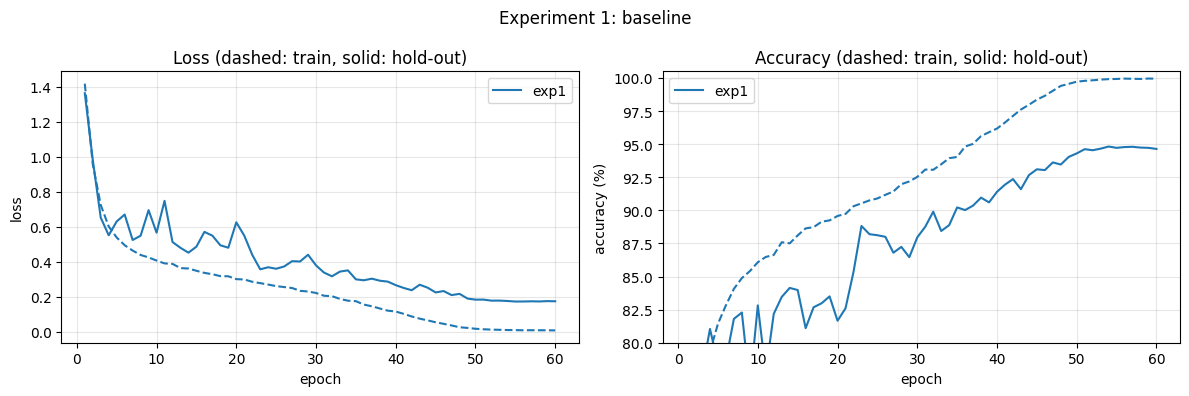

In [11]:
_, results["exp1: A, crop+flip"] = run_experiment("exp1_baseline", model="A", epochs=EP)
plot_history({"exp1": results["exp1: A, crop+flip"]}, "Experiment 1: baseline")

### Experiment 2: stronger regularization
Same model, plus Cutout (8×8) and label smoothing 0.1.

[exp2_regularized] model A, 2,777,674 parameters | {'model': 'A', 'epochs': 60, 'cutout': 8, 'label_smoothing': 0.1, 'lr': 0.1, 'weight_decay': 0.0005, 'batch_size': 128, 'warmup_epochs': 2, 'seed': 0}
[exp2_regularized] found checkpoint with 60/60 epochs done
  epoch   5 | train loss 0.985 acc 79.65% | hold-out loss 0.722 acc 76.82% (saved)
  epoch  10 | train loss 0.866 acc 84.84% | hold-out loss 0.580 acc 82.20% (saved)
  epoch  15 | train loss 0.814 acc 87.23% | hold-out loss 0.505 acc 84.16% (saved)
  epoch  20 | train loss 0.782 acc 88.58% | hold-out loss 0.539 acc 84.16% (saved)
  epoch  25 | train loss 0.752 acc 90.07% | hold-out loss 0.391 acc 88.84% (saved)
  epoch  30 | train loss 0.715 acc 91.56% | hold-out loss 0.355 acc 90.02% (saved)
  epoch  35 | train loss 0.676 acc 93.36% | hold-out loss 0.322 acc 91.50% (saved)
  epoch  40 | train loss 0.634 acc 95.22% | hold-out loss 0.307 acc 91.90% (saved)
  epoch  45 | train loss 0.585 acc 97.30% | hold-out loss 0.268 acc 93.52% 

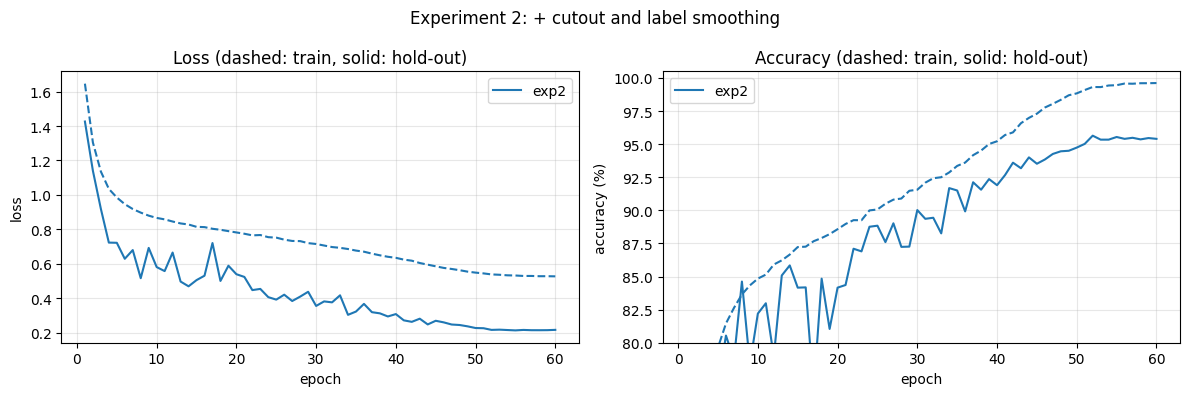

In [12]:
_, results["exp2: A, +cutout +LS"] = run_experiment("exp2_regularized", model="A", epochs=EP,
                                                    cutout=8, label_smoothing=0.1)
plot_history({"exp2": results["exp2: A, +cutout +LS"]}, "Experiment 2: + cutout and label smoothing")

### Experiment 3: deeper model
Model B (three blocks per stage) with the training recipe of experiment 2.

[exp3_deeper] model B, 4,327,754 parameters | {'model': 'B', 'epochs': 60, 'cutout': 8, 'label_smoothing': 0.1, 'lr': 0.1, 'weight_decay': 0.0005, 'batch_size': 128, 'warmup_epochs': 2, 'seed': 0}
[exp3_deeper] found checkpoint with 60/60 epochs done
  epoch   5 | train loss 0.983 acc 79.30% | hold-out loss 0.708 acc 77.78% (saved)
  epoch  10 | train loss 0.870 acc 83.96% | hold-out loss 0.579 acc 82.44% (saved)
  epoch  15 | train loss 0.816 acc 86.61% | hold-out loss 0.488 acc 86.24% (saved)
  epoch  20 | train loss 0.780 acc 88.04% | hold-out loss 0.510 acc 84.98% (saved)
  epoch  25 | train loss 0.748 acc 89.49% | hold-out loss 0.386 acc 88.92% (saved)
  epoch  30 | train loss 0.710 acc 91.19% | hold-out loss 0.360 acc 90.08% (saved)
  epoch  35 | train loss 0.670 acc 92.89% | hold-out loss 0.336 acc 91.14% (saved)
  epoch  40 | train loss 0.630 acc 94.70% | hold-out loss 0.303 acc 92.68% (saved)
  epoch  45 | train loss 0.578 acc 96.96% | hold-out loss 0.286 acc 93.28% (saved)
  

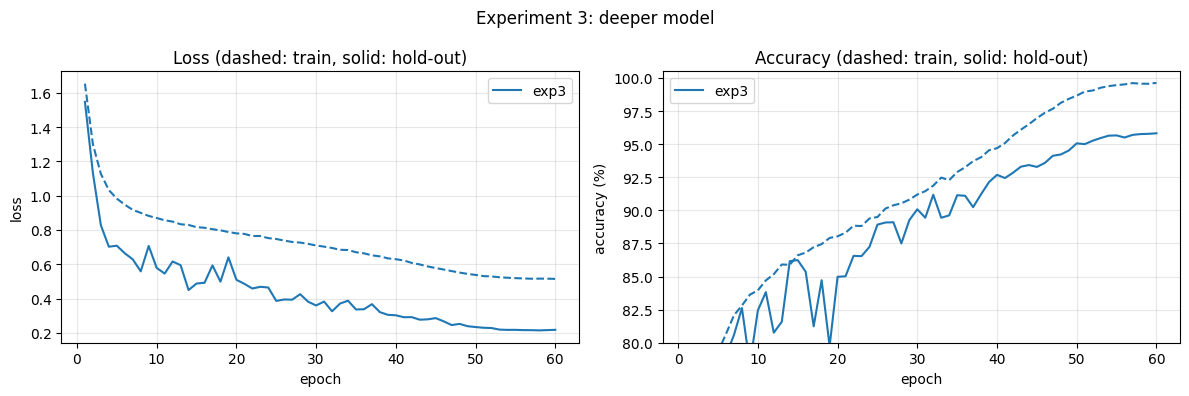

In [13]:
_, results["exp3: B, +cutout +LS"] = run_experiment("exp3_deeper", model="B", epochs=EP,
                                                    cutout=8, label_smoothing=0.1)
plot_history({"exp3": results["exp3: B, +cutout +LS"]}, "Experiment 3: deeper model")

### Comparison

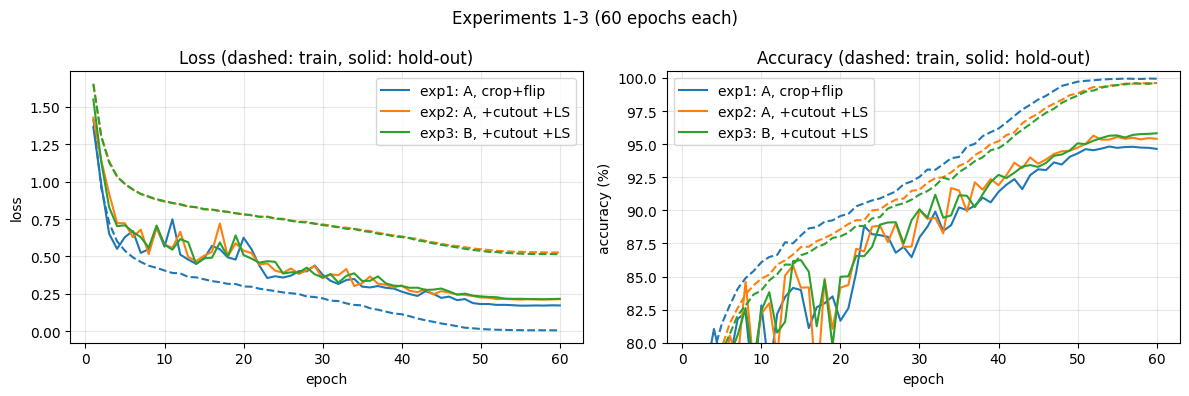

,experiment,model,parameters,epochs,cutout,label smoothing,train acc (%),hold-out acc (%),train time (min)
0,1 baseline,A,"2,777,674",60,0,0.0,99.94,94.64,10.6
1,"2 + cutout, label smoothing",A,"2,777,674",60,8,0.1,99.61,95.40,10.7
2,3 deeper model,B,"4,327,754",60,8,0.1,99.63,95.82,15.5


In [14]:
plot_history(results, f"Experiments 1-3 ({EP} epochs each)")

def summarize(name, run):
    with open(os.path.join(OUT_DIR, run, "history.json")) as f:
        d = json.load(f)
    last = d["history"][-1]
    return {"experiment": name, "model": d["config"]["model"], "parameters": f"{d['n_params']:,}",
            "epochs": len(d["history"]), "cutout": d["config"]["cutout"],
            "label smoothing": d["config"]["label_smoothing"],
            "train acc (%)": round(last["train_acc"], 2), "hold-out acc (%)": round(last["val_acc"], 2),
            "train time (min)": round(sum(h["seconds"] for h in d["history"]) / 60, 1)}

table = pd.DataFrame([summarize("1 baseline", "exp1_baseline"),
                      summarize("2 + cutout, label smoothing", "exp2_regularized"),
                      summarize("3 deeper model", "exp3_deeper")])
table

## 6. Final model

The better of experiments 2 and 3 (by hold-out accuracy) is retrained from scratch for more epochs with the same settings. The reported accuracy is taken at the **last epoch** (no early stopping on the hold-out set).

Selected architecture: model B
[final] model B, 4,327,754 parameters | {'model': 'B', 'epochs': 200, 'cutout': 8, 'label_smoothing': 0.1, 'lr': 0.1, 'weight_decay': 0.0005, 'batch_size': 128, 'warmup_epochs': 2, 'seed': 0}
[final] found checkpoint with 200/200 epochs done
  epoch   5 | train loss 0.983 acc 79.33% | hold-out loss 0.691 acc 77.48% (saved)
  epoch  10 | train loss 0.876 acc 83.96% | hold-out loss 0.655 acc 79.32% (saved)
  epoch  15 | train loss 0.831 acc 85.82% | hold-out loss 0.594 acc 82.12% (saved)
  epoch  20 | train loss 0.803 acc 87.20% | hold-out loss 0.598 acc 81.36% (saved)
  epoch  25 | train loss 0.790 acc 87.74% | hold-out loss 0.519 acc 83.82% (saved)
  epoch  30 | train loss 0.775 acc 88.27% | hold-out loss 0.458 acc 86.88% (saved)
  epoch  35 | train loss 0.769 acc 88.65% | hold-out loss 0.451 acc 86.62% (saved)
  epoch  40 | train loss 0.762 acc 88.94% | hold-out loss 0.478 acc 86.16% (saved)
  epoch  45 | train loss 0.753 acc 89.27% | hold-out loss 0.476

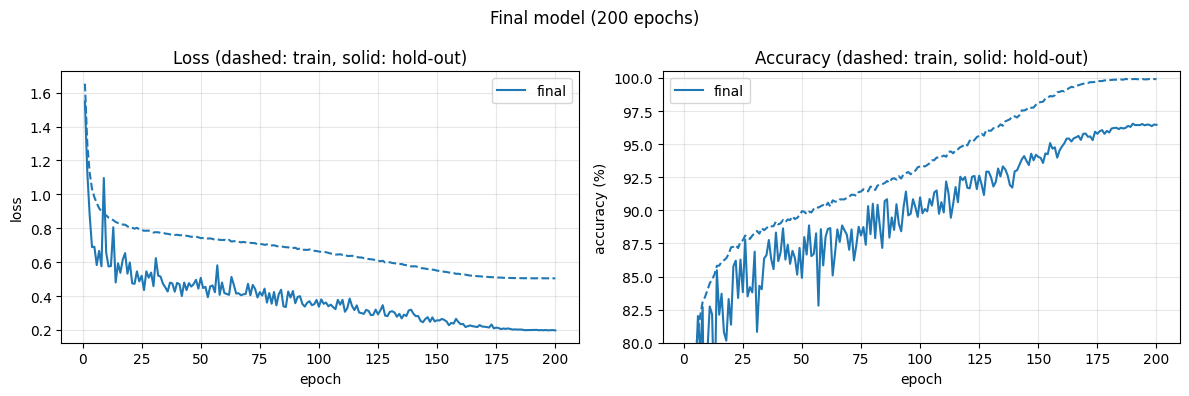

In [15]:
best = "B" if results["exp3: B, +cutout +LS"][-1]["val_acc"] >= results["exp2: A, +cutout +LS"][-1]["val_acc"] else "A"
print("Selected architecture: model", best)
final_model, final_hist = run_experiment("final", model=best, epochs=EP_FINAL, cutout=8, label_smoothing=0.1)
plot_history({"final": final_hist}, f"Final model ({EP_FINAL} epochs)")

In [16]:
_, acc_plain = evaluate(final_model, Xho, yho)
_, acc_tta = evaluate(final_model, Xho, yho, tta=True)
n_final = count_params(final_model)

print("=" * 60)
print(f"Final model: ResNet {MODELS[best]}")
print(f"Number of trainable parameters: {n_final:,}  (limit 5,000,000)")
print(f"Final test accuracy on the {len(Xho):,} hold-out images: {acc_plain:.2f}%")
print(f"Same, with horizontal-flip test-time augmentation: {acc_tta:.2f}%")
print("=" * 60)

Final model: ResNet {'widths': (64, 128, 256), 'blocks': (3, 3, 3)}
Number of trainable parameters: 4,327,754  (limit 5,000,000)
Final test accuracy on the 5,000 hold-out images: 96.46%
Same, with horizontal-flip test-time augmentation: 96.78%


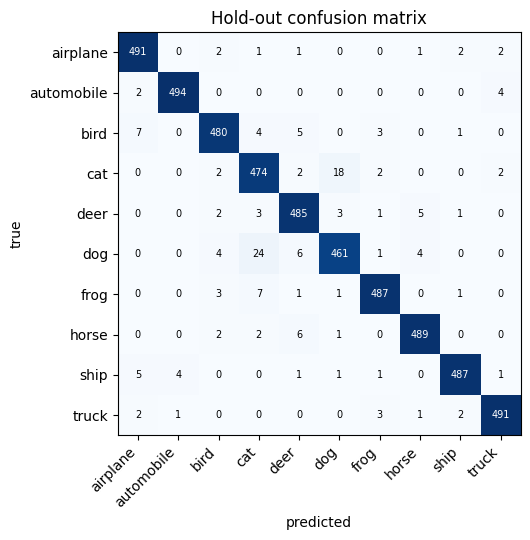

Per-class accuracy (%): {'airplane': 98.2, 'automobile': 98.8, 'bird': 96.0, 'cat': 94.8, 'deer': 97.0, 'dog': 92.2, 'frog': 97.4, 'horse': 97.8, 'ship': 97.4, 'truck': 98.2}


In [17]:
# Per-class accuracy and confusion matrix on the hold-out set
pred = predict_proba(final_model, Xho, tta=True).argmax(1)
cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(yho.cpu(), pred.cpu()):
    cm[t, p] += 1
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set(xticks=range(10), yticks=range(10), xlabel="predicted", ylabel="true", title="Hold-out confusion matrix")
ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.tight_layout(); plt.show()
print("Per-class accuracy (%):", {c: round(cm[i, i].item() / cm[i].sum().item() * 100, 1) for i, c in enumerate(CLASSES)})

## 7. Kaggle submission

Predictions for the 2,000 test images (with flip TTA), written in the format of `sample_submission.csv`.

In [18]:
test_pred = predict_proba(final_model, Xte, tta=True).argmax(1).cpu().numpy()
sample = pd.read_csv(os.path.join(DATA_ROOT, "sample_submission.csv"))
submission = pd.DataFrame({"id": test_df.id.values, "label": test_pred})
assert list(submission.columns) == list(sample.columns) and (submission.id.values == sample.id.values).all()
assert submission.label.between(0, 9).all() and len(submission) == len(sample)

sub_path = os.path.join(OUT_DIR, "submission.csv")
submission.to_csv(sub_path, index=False)
submission.to_csv("submission.csv", index=False)
print("Saved", sub_path, "|", len(submission), "rows")
print("Predicted class counts:", np.bincount(test_pred, minlength=10))
submission.head()

Saved /content/drive/MyDrive/dl-project1/runs/submission.csv | 2000 rows
Predicted class counts: [173 218 216 223 190 202 182 199 208 189]


,id,label
0,0,6
1,1,3
2,2,3
3,3,9
4,4,3


## 8. Experiment 4: robustness to the shifted test set

**Observation.** The final model reaches 96.46% on the hold-out images but only **0.867 (public) / 0.827 (private)** on Kaggle. The Kaggle test images are described as a separate held-out version of CIFAR-10, so this gap of roughly 10 to 14 points indicates a distribution shift between the training images and the test images, not ordinary overfitting (the hold-out images were never trained on).

**Experiment.** Model B is trained again with exactly the same settings as the final model, plus the stronger augmentation defined in section 2. To measure robustness without touching the test set, both models are also evaluated on a *perturbed* copy of the hold-out set (the same strong augmentation applied once with a fixed seed).

[exp4_strong_aug] model B, 4,327,754 parameters | {'model': 'B', 'epochs': 200, 'cutout': 8, 'label_smoothing': 0.1, 'lr': 0.1, 'weight_decay': 0.0005, 'batch_size': 128, 'warmup_epochs': 2, 'seed': 0, 'strong_aug': True}
  epoch   1 | train loss 1.825 acc 38.41% | hold-out loss 1.403 acc 52.42% | 15s
  epoch   2 | train loss 1.490 acc 55.85% | hold-out loss 1.079 acc 63.02% | 15s
  epoch   3 | train loss 1.327 acc 63.56% | hold-out loss 0.823 acc 72.22% | 15s
  epoch   4 | train loss 1.234 acc 67.76% | hold-out loss 0.751 acc 75.76% | 16s
  epoch   5 | train loss 1.171 acc 70.88% | hold-out loss 0.868 acc 71.16% | 16s
  epoch   6 | train loss 1.139 acc 72.26% | hold-out loss 0.682 acc 78.28% | 17s
  epoch   7 | train loss 1.107 acc 73.43% | hold-out loss 0.783 acc 74.44% | 16s
  epoch   8 | train loss 1.081 acc 74.60% | hold-out loss 0.734 acc 75.22% | 16s
  epoch   9 | train loss 1.065 acc 75.21% | hold-out loss 0.641 acc 79.70% | 16s
  epoch  10 | train loss 1.053 acc 76.04% | hold-

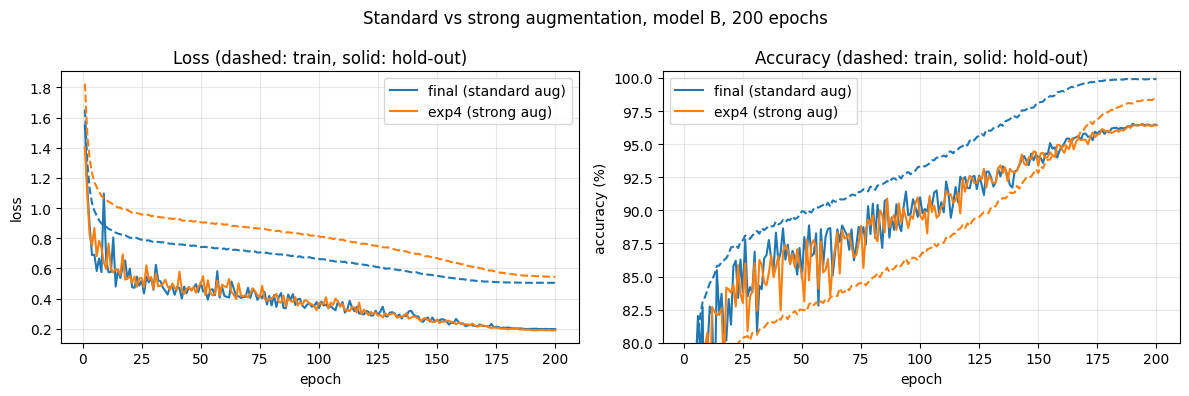

In [19]:
exp4_model, exp4_hist = run_experiment("exp4_strong_aug", model="B", epochs=EP_FINAL, cutout=8,
                                       label_smoothing=0.1, strong_aug=True)
plot_history({"final (standard aug)": final_hist, "exp4 (strong aug)": exp4_hist},
             f"Standard vs strong augmentation, model B, {EP_FINAL} epochs")

In [20]:
# Perturbed hold-out set: strong augmentation applied once, fixed seed, stored as uint8 like the real data
torch.manual_seed(123)
Xho_shift = (strong_augment(Xho.float() / 255) * 255).round().to(torch.uint8)

rows = []
for label, m in [("final (standard aug)", final_model), ("exp4 (strong aug)", exp4_model)]:
    rows.append({"model": label, "parameters": f"{count_params(m):,}",
                 "hold-out acc (%)": round(evaluate(m, Xho, yho, tta=True)[1], 2),
                 "perturbed hold-out acc (%)": round(evaluate(m, Xho_shift, yho, tta=True)[1], 2)})
robust_table = pd.DataFrame(rows)
print("Accuracy with flip TTA")
robust_table

Accuracy with flip TTA


,model,parameters,hold-out acc (%),perturbed hold-out acc (%)
0,final (standard aug),"4,327,754",96.78,75.32
1,exp4 (strong aug),"4,327,754",96.80,94.36


In [21]:
test_pred4 = predict_proba(exp4_model, Xte, tta=True).argmax(1).cpu().numpy()
submission4 = pd.DataFrame({"id": test_df.id.values, "label": test_pred4})
assert (submission4.id.values == sample.id.values).all() and submission4.label.between(0, 9).all()
sub4_path = os.path.join(OUT_DIR, "submission_exp4.csv")
submission4.to_csv(sub4_path, index=False)
print("Saved", sub4_path, "|", len(submission4), "rows")
print("Predicted class counts:", np.bincount(test_pred4, minlength=10))
print(f"Test predictions that differ from the final model: {(test_pred4 != test_pred).mean() * 100:.1f}%")

print("=" * 60)
print(f"Experiment 4 model: ResNet {MODELS['B']}")
print(f"Number of trainable parameters: {count_params(exp4_model):,}  (limit 5,000,000)")
print(f"Test accuracy on the {len(Xho):,} hold-out images (flip TTA): {evaluate(exp4_model, Xho, yho, tta=True)[1]:.2f}%")
print("=" * 60)

Saved /content/drive/MyDrive/dl-project1/runs/submission_exp4.csv | 2000 rows
Predicted class counts: [157 217 202 215 192 211 182 203 212 209]
Test predictions that differ from the final model: 10.2%
Experiment 4 model: ResNet {'widths': (64, 128, 256), 'blocks': (3, 3, 3)}
Number of trainable parameters: 4,327,754  (limit 5,000,000)
Test accuracy on the 5,000 hold-out images (flip TTA): 96.80%


## 9. Test-time adaptation (disclosed)

Two prediction-time techniques that the instructor explicitly allowed on the course Slack. **Both use the unlabeled test images, and no labels.** The model weights are not changed.

1. **Test-time BatchNorm adaptation.** The running mean and variance stored in every BatchNorm layer are replaced by the statistics of the images being predicted (here: the 2,000 test images). This corrects for changes in the input statistics, such as different brightness, contrast, blur or noise levels.
2. **Class-balanced prediction.** The softmax probabilities are rescaled per class so that every class receives an equal share of the total probability mass, then the argmax is taken. This assumes the test set is roughly class-balanced.

Before using them on the test set, both are checked on the hold-out set and on its perturbed copy, where labels are available.

In [22]:
import copy

@torch.no_grad()
def adapt_batchnorm(model, X, bs=500):
    # Returns a copy of `model` whose BatchNorm statistics are recomputed from the images X (no labels used).
    m = copy.deepcopy(model)
    for layer in m.modules():
        if isinstance(layer, nn.BatchNorm2d):
            layer.reset_running_stats()
            layer.momentum = None            # cumulative average over all batches
    m.train()                                # BN layers update their statistics in train mode
    for i in range(0, len(X), bs):
        x = normalize(X[i:i + bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast(device.type, enabled=device.type == "cuda"):
            m(x); m(x.flip(3))
    return m.eval()

def balance_classes(p, iters=100):
    # Rescale class probabilities so that every class gets the same total mass (1 / num_classes).
    w = torch.ones(p.size(1), device=p.device)
    for _ in range(iters):
        q = p * w
        q = q / q.sum(1, keepdim=True)
        w = w * (1 / p.size(1)) / q.mean(0)
    return q

def acc(p, y):
    return round((p.argmax(1) == y).float().mean().item() * 100, 2)

rows = []
for label, m in [("final (standard aug)", final_model), ("exp4 (strong aug)", exp4_model)]:
    for set_name, X in [("hold-out", Xho), ("perturbed hold-out", Xho_shift)]:
        p_plain = predict_proba(m, X, tta=True)
        p_bn = predict_proba(adapt_batchnorm(m, X), X, tta=True)
        rows.append({"model": label, "evaluated on": set_name,
                     "flip TTA (%)": acc(p_plain, yho),
                     "+ BN adaptation (%)": acc(p_bn, yho),
                     "+ BN adaptation + class balance (%)": acc(balance_classes(p_bn), yho)})
adapt_table = pd.DataFrame(rows)
adapt_table

,model,evaluated on,flip TTA (%),+ BN adaptation (%),+ BN adaptation + class balance (%)
0,final (standard aug),hold-out,96.78,96.54,96.56
1,final (standard aug),perturbed hold-out,75.32,80.80,80.74
2,exp4 (strong aug),hold-out,96.80,96.60,96.58
3,exp4 (strong aug),perturbed hold-out,94.36,94.06,94.08


In [23]:
# Test-set predictions with the adaptation techniques (BatchNorm statistics come from the 2,000 test images)
adapted_preds = {}
for tag, m in [("final", final_model), ("exp4", exp4_model)]:
    p_bn = predict_proba(adapt_batchnorm(m, Xte), Xte, tta=True)
    adapted_preds[f"{tag}_bn"] = p_bn.argmax(1).cpu().numpy()
    adapted_preds[f"{tag}_bn_balanced"] = balance_classes(p_bn).argmax(1).cpu().numpy()

for tag, pred_ in adapted_preds.items():
    path = os.path.join(OUT_DIR, f"submission_{tag}.csv")
    pd.DataFrame({"id": test_df.id.values, "label": pred_}).to_csv(path, index=False)
    base = test_pred if tag.startswith("final") else test_pred4
    print(f"Saved {path} | class counts {np.bincount(pred_, minlength=10)} "
          f"| {(pred_ != base).mean() * 100:.1f}% of predictions changed vs. no adaptation")

Saved /content/drive/MyDrive/dl-project1/runs/submission_final_bn.csv | class counts [170 212 212 209 195 201 186 205 214 196] | 4.1% of predictions changed vs. no adaptation
Saved /content/drive/MyDrive/dl-project1/runs/submission_final_bn_balanced.csv | class counts [190 209 210 208 196 198 189 200 203 197] | 4.6% of predictions changed vs. no adaptation
Saved /content/drive/MyDrive/dl-project1/runs/submission_exp4_bn.csv | class counts [157 221 201 206 193 219 187 206 217 193] | 3.3% of predictions changed vs. no adaptation
Saved /content/drive/MyDrive/dl-project1/runs/submission_exp4_bn_balanced.csv | class counts [175 217 197 211 194 210 189 204 209 194] | 3.5% of predictions changed vs. no adaptation


## References

* K. He, X. Zhang, S. Ren, J. Sun. *Deep Residual Learning for Image Recognition.* CVPR 2016.
* T. DeVries, G. Taylor. *Improved Regularization of Convolutional Neural Networks with Cutout.* arXiv:1708.04552, 2017.
* C. Szegedy et al. *Rethinking the Inception Architecture for Computer Vision.* CVPR 2016 (label smoothing).
* I. Loshchilov, F. Hutter. *SGDR: Stochastic Gradient Descent with Warm Restarts.* ICLR 2017 (cosine learning-rate schedule).
* D. Hendrycks, T. Dietterich. *Benchmarking Neural Network Robustness to Common Corruptions and Perturbations.* ICLR 2019.
* B. Recht, R. Roelofs, L. Schmidt, V. Shankar. *Do CIFAR-10 Classifiers Generalize to CIFAR-10?* arXiv:1806.00451, 2018.
* Z. Nado et al. *Evaluating Prediction-Time Batch Normalization for Robustness under Covariate Shift.* arXiv:2006.10963, 2020.
* S. Schneider et al. *Improving Robustness against Common Corruptions by Covariate Shift Adaptation.* NeurIPS 2020.
* A. Krizhevsky. *Learning Multiple Layers of Features from Tiny Images.* 2009 (CIFAR-10).